# Практическая работа № 1
## Основы построения, обучения и визуализации нейронных сетей в PyTorch

**Ф.И.О.:** ____________________  
**Группа:** ____________________

### Цель работы
Освоить полный цикл классификации изображений: подготовку данных, создание и обучение нейронной сети, оценку качества и визуальное объяснение решений модели.

**Как работать:** запустите ячейки сверху вниз. В Google Colab рекомендуется выбрать **Среда выполнения → Сменить среду выполнения → GPU**. Результаты обучения зависят от доступного оборудования, версий библиотек и времени выполнения; в отчёт следует переносить фактические значения из вывода ноутбука.

### Важно
- Не устанавливайте принудительно старые версии PyTorch/torchvision.
- Для ускорения можно ограничить объём датасета в ячейке настроек. Для итогового отчёта желательно оставить `None` и использовать полный набор данных, если хватает времени и памяти.
- Наборы данных могут быть большими и скачиваться несколько минут.

In [1]:
# Установка только дополнительных библиотек; установленный PyTorch не понижаем
%pip -q install torchcam opencv-python-headless scikit-learn

In [2]:
import os, random, json, time, copy, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.models import resnet18, resnet50, ResNet18_Weights, ResNet50_Weights
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from torchcam.methods import SmoothGradCAMpp
from torchvision.transforms.functional import to_pil_image

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Устройство:", device)
print("CUDA доступна:", torch.cuda.is_available())
OUT = Path("/content/results") if Path("/content").exists() else Path("results")
OUT.mkdir(parents=True, exist_ok=True)
DATA = Path("/content/data") if Path("/content").exists() else Path("data")
DATA.mkdir(parents=True, exist_ok=True)

# Настройки вычислительной нагрузки. None означает полный датасет.
# Если время ограничено, задайте например 12000 для train и 3000 для test.
AIRCRAFT_TRAIN_LIMIT = None
AIRCRAFT_TEST_LIMIT = None
GTSRB_TRAIN_LIMIT = None
GTSRB_TEST_LIMIT = None
BATCH_AIRCRAFT = 32
BATCH_GTSRB = 64
NUM_WORKERS = 2

PyTorch: 2.11.0+cu130
Устройство: cuda
CUDA доступна: True


## Раздел 1. Классификация изображений FashionMNIST

FashionMNIST содержит 10 категорий одежды. В этом разделе используется полносвязная нейронная сеть, `CrossEntropyLoss` и SGD с `lr=0.001`. Размер батча — 64, число эпох — 5.

In [3]:
fashion_transform = transforms.ToTensor()
fashion_train = datasets.FashionMNIST(DATA, train=True, download=True, transform=fashion_transform)
fashion_test = datasets.FashionMNIST(DATA, train=False, download=True, transform=fashion_transform)
fashion_classes = fashion_train.classes
print("Классы:", fashion_classes)
print("Обучающих объектов:", len(fashion_train))
print("Тестовых объектов:", len(fashion_test))
train_loader_fashion = DataLoader(fashion_train, batch_size=64, shuffle=True, num_workers=NUM_WORKERS)
test_loader_fashion = DataLoader(fashion_test, batch_size=64, shuffle=False, num_workers=NUM_WORKERS)
xb, yb = next(iter(train_loader_fashion))
print("Форма батча изображений (N,C,H,W):", tuple(xb.shape))
print("Форма батча меток:", tuple(yb.shape))
print("N — количество изображений; C — число каналов; H — высота; W — ширина.")

100%|██████████| 26.4M/26.4M [00:00<00:00, 115MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 4.66MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 65.4MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 15.3MB/s]


Классы: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Обучающих объектов: 60000
Тестовых объектов: 10000
Форма батча изображений (N,C,H,W): (64, 1, 28, 28)
Форма батча меток: (64,)
N — количество изображений; C — число каналов; H — высота; W — ширина.


In [4]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.layers = nn.Sequential(
            nn.Linear(28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )
    def forward(self, x):
        return self.layers(self.flatten(x))

fashion_model = NeuralNetwork().to(device)
loss_fn_fashion = nn.CrossEntropyLoss()
optimizer_fashion = torch.optim.SGD(fashion_model.parameters(), lr=0.001)
print(fashion_model)

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)


In [5]:
def train_one_epoch(model, loader, loss_fn, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        total += y.size(0)
    return total_loss / max(total, 1), correct / max(total, 1)

@torch.no_grad()
def evaluate_model(model, loader, loss_fn, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    ys, preds = [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = loss_fn(logits, y)
        total_loss += loss.item() * x.size(0)
        p = logits.argmax(1)
        correct += (p == y).sum().item()
        total += y.size(0)
        ys.extend(y.cpu().numpy().tolist())
        preds.extend(p.cpu().numpy().tolist())
    return total_loss / max(total, 1), correct / max(total, 1), np.array(ys), np.array(preds)

fashion_history = {"epoch": [], "train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
for epoch in range(1, 6):
    tr_loss, tr_acc = train_one_epoch(fashion_model, train_loader_fashion, loss_fn_fashion, optimizer_fashion, device)
    te_loss, te_acc, _, _ = evaluate_model(fashion_model, test_loader_fashion, loss_fn_fashion, device)
    for k, v in [("epoch", epoch), ("train_loss", tr_loss), ("train_acc", tr_acc), ("test_loss", te_loss), ("test_acc", te_acc)]:
        fashion_history[k].append(v)
    print(f"Эпоха {epoch}/5 | train loss={tr_loss:.4f}, train acc={tr_acc:.2%} | test loss={te_loss:.4f}, test acc={te_acc:.2%}")

import pandas as pd
fashion_table = pd.DataFrame({
    "Эпоха": fashion_history["epoch"],
    "Точность на тесте, %": np.round(np.array(fashion_history["test_acc"])*100, 2),
    "Средняя ошибка на тесте": np.round(fashion_history["test_loss"], 4)
})
display(fashion_table)
fashion_table.to_csv(OUT / "fashionmnist_results.csv", index=False)
torch.save(fashion_model.state_dict(), OUT / "fashionmnist_model.pt")

Эпоха 1/5 | train loss=2.2483, train acc=23.18% | test loss=2.1866, test acc=32.69%
Эпоха 2/5 | train loss=2.0924, train acc=43.29% | test loss=1.9728, test acc=50.35%
Эпоха 3/5 | train loss=1.7981, train acc=53.80% | test loss=1.6179, test acc=58.00%
Эпоха 4/5 | train loss=1.4535, train acc=61.61% | test loss=1.3186, test acc=63.41%
Эпоха 5/5 | train loss=1.2107, train acc=64.66% | test loss=1.1309, test acc=64.48%


,Эпоха,"Точность на тесте, %",Средняя ошибка на тесте
0,1,32.69,2.1866
1,2,50.35,1.9728
2,3,58.00,1.6179
3,4,63.41,1.3186
4,5,64.48,1.1309


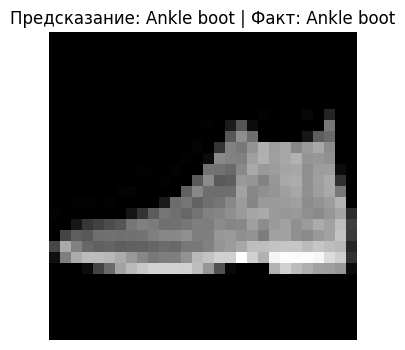

Предсказанный класс: Ankle boot
Фактический класс: Ankle boot


In [6]:
# Проверка на одном тестовом изображении
idx = 0
image_tensor, true_label = fashion_test[idx]
fashion_model.eval()
with torch.no_grad():
    predicted_label = fashion_model(image_tensor.unsqueeze(0).to(device)).argmax(1).item()
plt.figure(figsize=(4,4))
plt.imshow(image_tensor.squeeze(0), cmap="gray")
plt.title(f"Предсказание: {fashion_classes[predicted_label]} | Факт: {fashion_classes[true_label]}")
plt.axis("off")
plt.savefig(OUT / "fashionmnist_example.png", bbox_inches="tight", dpi=150)
plt.show()
print("Предсказанный класс:", fashion_classes[predicted_label])
print("Фактический класс:", fashion_classes[true_label])

### Краткий анализ раздела 1
`Flatten` преобразует изображение в одномерный вектор признаков; полносвязные слои изучают связи между признаками; `ReLU` добавляет нелинейность. Точность и средняя ошибка после каждой эпохи сохранены в таблице и `fashionmnist_results.csv`. В выводе отчёта используйте полученные значения.

## Раздел 2. Визуализация решения ResNet18 для `cat.jpg`

Предобученная ResNet18 выдаёт предсказание ImageNet. SmoothGradCAMpp показывает области изображения, связанные с выбранным классом. Карта активации не является доказательством причинности, поэтому её необходимо оценивать визуально.

In [7]:
# Загрузите cat.jpg в Colab через панель Files либо выберите файл вручную.
from google.colab import files
if not Path("cat.jpg").exists():
    print("Загрузите файл cat.jpg:")
    uploaded = files.upload()
    if "cat.jpg" in uploaded:
        print("cat.jpg загружен")

In [8]:
cat_path = Path("cat.jpg")
if not cat_path.exists():
    # Для локального Jupyter допускается путь в текущей директории
    raise FileNotFoundError("Не найден cat.jpg. Загрузите изображение cat.jpg в корень файловой панели Colab.")
cat_image = Image.open(cat_path).convert("RGB")
weights18 = ResNet18_Weights.DEFAULT
preprocess18 = weights18.transforms()
cat_input = preprocess18(cat_image).unsqueeze(0).to(device)
model18 = resnet18(weights=weights18).to(device).eval()
cam_extractor18 = SmoothGradCAMpp(model18, target_layer="layer4")
with torch.no_grad():
    logits18 = model18(cat_input)
    probs18 = torch.softmax(logits18, dim=1)
    class_id18 = int(logits18.argmax(1).item())
class_name18 = weights18.meta["categories"][class_id18]
print(f"Предсказание ResNet18: {class_name18} (индекс {class_id18}), вероятность {probs18[0,class_id18].item():.2%}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 177MB/s]


Предсказание ResNet18: tabby (индекс 281), вероятность 57.30%


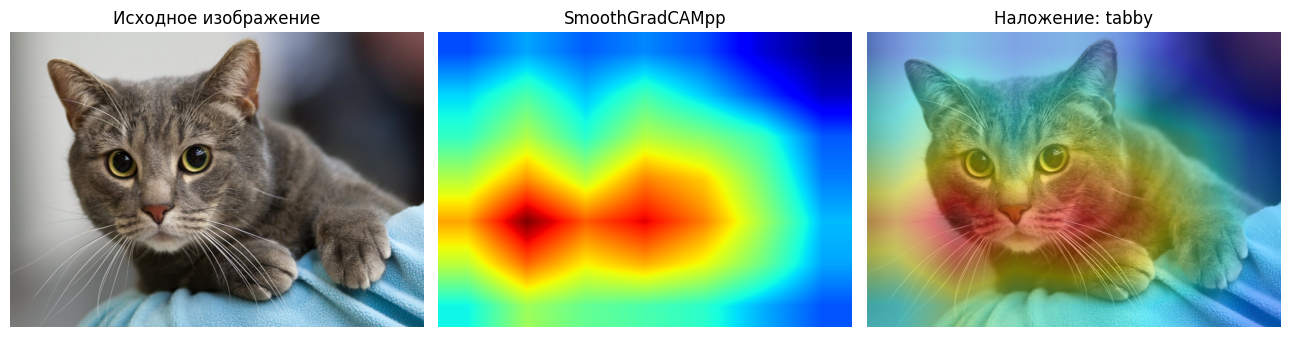

Сохранено: /content/results/output.jpg


In [10]:
# SmoothGradCAMpp получает logits для целевого класса и возвращает карту активации
logits_cam18 = model18(cat_input)
activation18 = cam_extractor18(class_id18, logits_cam18)[0].detach().cpu().squeeze().numpy()
activation18 = np.maximum(activation18, 0)
activation18 = (activation18 - activation18.min()) / (activation18.max() - activation18.min() + 1e-8)
orig = np.array(cat_image)
heat = cv2.resize(activation18, (orig.shape[1], orig.shape[0]))
heat_color = cv2.applyColorMap(np.uint8(255 * heat), cv2.COLORMAP_JET)
heat_color = cv2.cvtColor(heat_color, cv2.COLOR_BGR2RGB)
overlay = cv2.addWeighted(orig, 0.60, heat_color, 0.40, 0)
plt.figure(figsize=(13,5))
plt.subplot(1,3,1); plt.imshow(orig); plt.title("Исходное изображение"); plt.axis("off")
plt.subplot(1,3,2); plt.imshow(heat, cmap="jet"); plt.title("SmoothGradCAMpp"); plt.axis("off")
plt.subplot(1,3,3); plt.imshow(overlay); plt.title(f"Наложение: {class_name18}"); plt.axis("off")
plt.tight_layout()
plt.savefig(OUT / "output.jpg", dpi=160, bbox_inches="tight")
plt.show()
print("Сохранено:", OUT / "output.jpg")

### Вопросы для отчёта — ResNet18
1. Какие области изображения выделены наиболее интенсивно? Опишите это по полученной карте.
2. Сосредоточено ли внимание модели на коте или на фоне?
3. Можно ли считать решение содержательно обоснованным? Укажите ограничения Grad-CAM.

## Раздел 3. Классификация самолётов FGVCAircraft

Используется уровень разметки `manufacturer`, предобученная ResNet50 и перенос обучения. Для обучающей выборки применяются размер 224×224, горизонтальное отражение, небольшой поворот и умеренные изменения цвета. Если скачивание FGVCAircraft завершается ошибкой из-за источника архива или сети, повторите ячейку позже либо проверьте доступность датасета в текущей версии torchvision.

In [11]:
aircraft_train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(8),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225])
])
aircraft_test_tf = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225])
])
aircraft_train_full = datasets.FGVCAircraft(root=str(DATA), split="train", annotation_level="manufacturer", download=True, transform=aircraft_train_tf)
aircraft_test_full = datasets.FGVCAircraft(root=str(DATA), split="test", annotation_level="manufacturer", download=True, transform=aircraft_test_tf)

def maybe_subset(dataset, limit, seed=SEED):
    if limit is None or limit >= len(dataset):
        return dataset
    g = torch.Generator().manual_seed(seed)
    indices = torch.randperm(len(dataset), generator=g)[:limit].tolist()
    return Subset(dataset, indices)

aircraft_train = maybe_subset(aircraft_train_full, AIRCRAFT_TRAIN_LIMIT)
aircraft_test = maybe_subset(aircraft_test_full, AIRCRAFT_TEST_LIMIT)
aircraft_classes = aircraft_train_full.classes
print("Классов производителей:", len(aircraft_classes))
print("Train:", len(aircraft_train), "| Test:", len(aircraft_test))
train_dl_aircraft = DataLoader(aircraft_train, batch_size=BATCH_AIRCRAFT, shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_dl_aircraft = DataLoader(aircraft_test, batch_size=BATCH_AIRCRAFT, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

100%|██████████| 2.75G/2.75G [00:30<00:00, 91.7MB/s]


Классов производителей: 30
Train: 3334 | Test: 3333


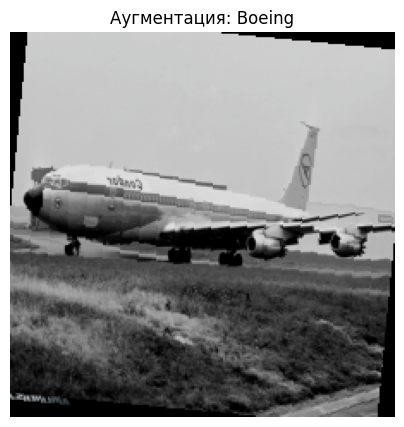

Проверьте, что преобразования сохраняют узнаваемость самолёта и не обрезают существенные части.


In [12]:
# Просмотр одного изображения после аугментации (денормализация только для показа)
x_aug, y_aug = aircraft_train[0]
x_show = x_aug.permute(1,2,0).numpy() * np.array([0.229,0.224,0.225]) + np.array([0.485,0.456,0.406])
plt.figure(figsize=(5,5)); plt.imshow(np.clip(x_show,0,1))
plt.title(f"Аугментация: {aircraft_classes[y_aug]}"); plt.axis("off")
plt.show()
print("Проверьте, что преобразования сохраняют узнаваемость самолёта и не обрезают существенные части.")

In [13]:
def make_resnet50(num_classes, pretrained=True):
    weights = ResNet50_Weights.DEFAULT if pretrained else None
    model = resnet50(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)

aircraft_model = make_resnet50(len(aircraft_classes), pretrained=True)
criterion_aircraft = nn.CrossEntropyLoss()
optimizer_aircraft = torch.optim.Adam(aircraft_model.parameters(), lr=0.0001)
aircraft_history = {"epoch": [], "train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
for epoch in range(1, 6):
    tr_loss, tr_acc = train_one_epoch(aircraft_model, train_dl_aircraft, criterion_aircraft, optimizer_aircraft, device)
    te_loss, te_acc, _, _ = evaluate_model(aircraft_model, test_dl_aircraft, criterion_aircraft, device)
    for k, v in [("epoch", epoch), ("train_loss", tr_loss), ("train_acc", tr_acc), ("test_loss", te_loss), ("test_acc", te_acc)]:
        aircraft_history[k].append(v)
    print(f"Эпоха {epoch}/5 | train loss={tr_loss:.4f}, train acc={tr_acc:.2%} | test loss={te_loss:.4f}, test acc={te_acc:.2%}")
pd.DataFrame(aircraft_history).to_csv(OUT / "aircraft_history.csv", index=False)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 177MB/s]


Эпоха 1/5 | train loss=2.5392, train acc=26.78% | test loss=1.9593, test acc=39.96%
Эпоха 2/5 | train loss=1.5663, train acc=53.27% | test loss=1.1225, test acc=64.00%
Эпоха 3/5 | train loss=0.8007, train acc=76.96% | test loss=0.7079, test acc=77.86%
Эпоха 4/5 | train loss=0.3911, train acc=90.10% | test loss=0.5601, test acc=81.46%
Эпоха 5/5 | train loss=0.2118, train acc=94.93% | test loss=0.4904, test acc=84.70%


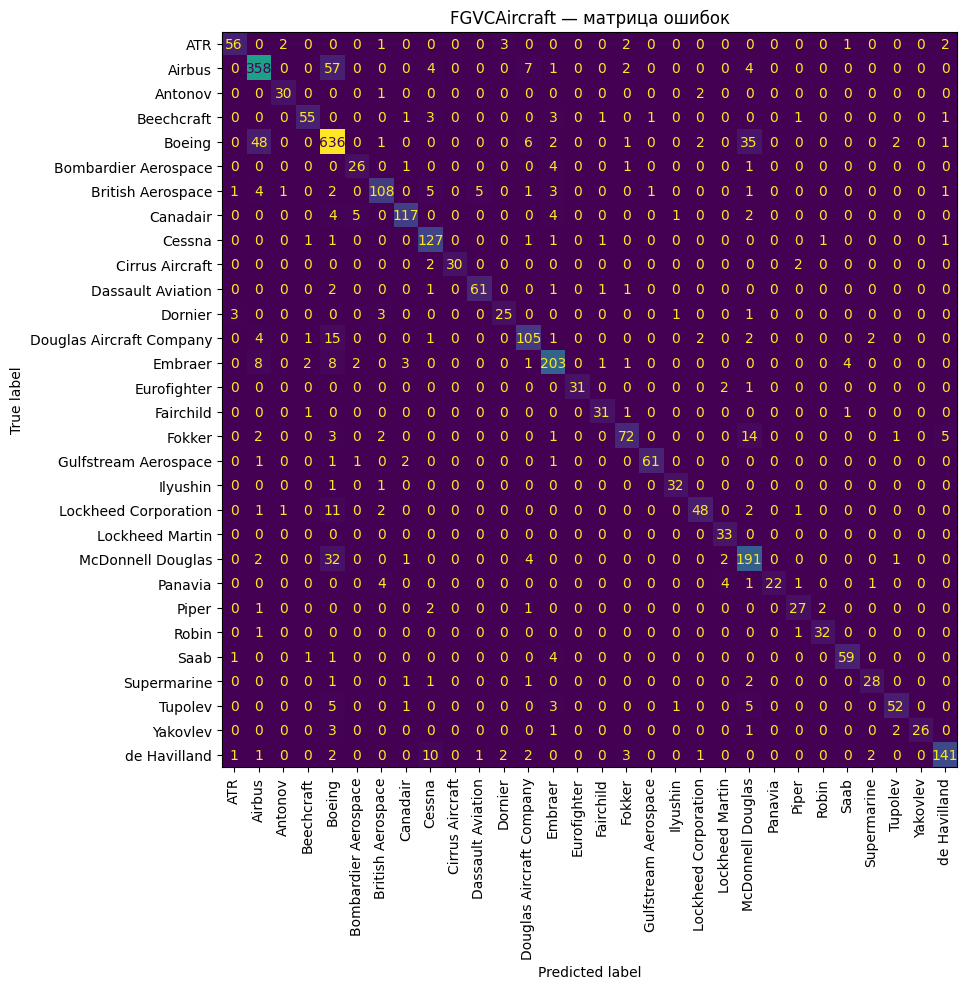

                          precision    recall  f1-score   support

                     ATR       0.90      0.84      0.87        67
                  Airbus       0.83      0.83      0.83       433
                 Antonov       0.88      0.91      0.90        33
              Beechcraft       0.90      0.83      0.87        66
                  Boeing       0.81      0.87      0.84       734
    Bombardier Aerospace       0.76      0.79      0.78        33
       British Aerospace       0.88      0.81      0.84       133
                Canadair       0.92      0.88      0.90       133
                  Cessna       0.81      0.95      0.88       134
         Cirrus Aircraft       1.00      0.88      0.94        34
       Dassault Aviation       0.91      0.91      0.91        67
                 Dornier       0.83      0.76      0.79        33
Douglas Aircraft Company       0.81      0.79      0.80       133
                 Embraer       0.87      0.87      0.87       233
         

In [14]:
# Матрица ошибок и classification_report
_, _, y_air, p_air = evaluate_model(aircraft_model, test_dl_aircraft, criterion_aircraft, device)
labels_air = list(range(len(aircraft_classes)))
cm_air = confusion_matrix(y_air, p_air, labels=labels_air)
fig, ax = plt.subplots(figsize=(12,10))
disp = ConfusionMatrixDisplay(cm_air, display_labels=aircraft_classes)
disp.plot(ax=ax, xticks_rotation=90, colorbar=False, values_format="d")
plt.title("FGVCAircraft — матрица ошибок")
plt.tight_layout()
plt.savefig(OUT / "aircraft_confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

report_air = classification_report(y_air, p_air, labels=labels_air, target_names=aircraft_classes, zero_division=0)
(OUT / "classification_report.txt").write_text(report_air, encoding="utf-8")
print(report_air)
# Наиболее часто путаемые пары классов (без диагонали)
cm_off = cm_air.copy()
np.fill_diagonal(cm_off, 0)
pairs = []
for i, j in zip(*np.where(cm_off > 0)):
    if i < j:
        pairs.append((int(cm_off[i,j] + cm_off[j,i]), aircraft_classes[i], aircraft_classes[j]))
print("Часто путаемые пары классов:")
for n, a, b in sorted(pairs, reverse=True)[:10]:
    print(f"{a} ↔ {b}: {n}")

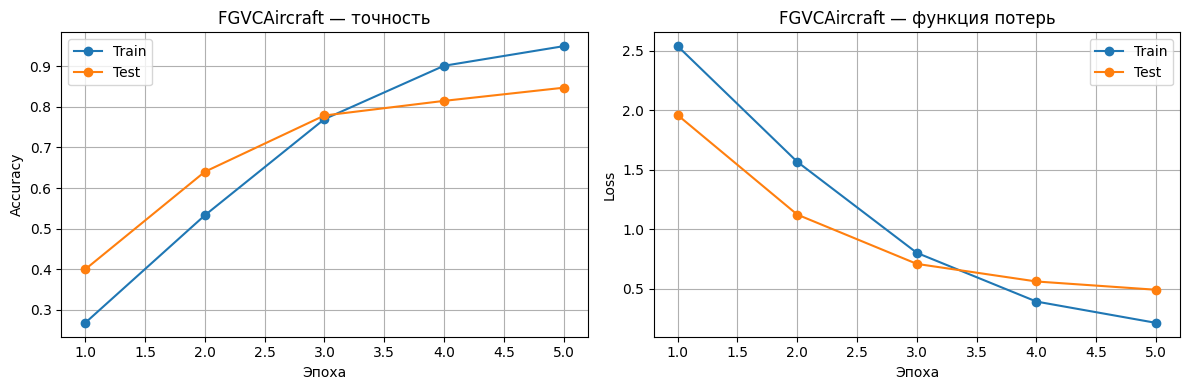

In [15]:
# Графики точности и ошибки
epochs_air = aircraft_history["epoch"]
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(epochs_air, aircraft_history["train_acc"], marker="o", label="Train")
axes[0].plot(epochs_air, aircraft_history["test_acc"], marker="o", label="Test")
axes[0].set_title("FGVCAircraft — точность"); axes[0].set_xlabel("Эпоха"); axes[0].set_ylabel("Accuracy"); axes[0].legend(); axes[0].grid(True)
axes[1].plot(epochs_air, aircraft_history["train_loss"], marker="o", label="Train")
axes[1].plot(epochs_air, aircraft_history["test_loss"], marker="o", label="Test")
axes[1].set_title("FGVCAircraft — функция потерь"); axes[1].set_xlabel("Эпоха"); axes[1].set_ylabel("Loss"); axes[1].legend(); axes[1].grid(True)
plt.tight_layout(); plt.savefig(OUT / "aircraft_training_curves.png", dpi=170); plt.show()

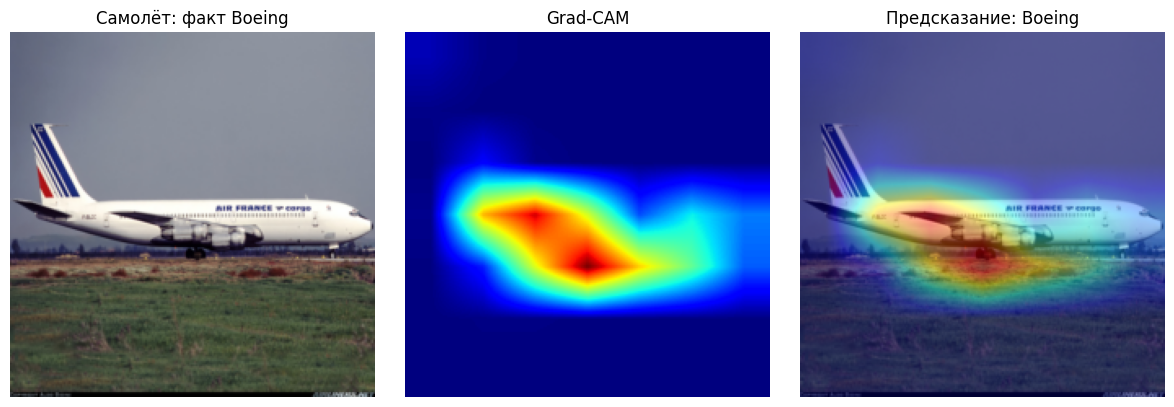

In [16]:
# Grad-CAM самолёта: выбранный тестовый объект
air_x, air_y = aircraft_test[0]
air_batch = air_x.unsqueeze(0).to(device)
cam_air = SmoothGradCAMpp(aircraft_model, target_layer="layer4")
air_logits = aircraft_model(air_batch)
air_pred = int(air_logits.argmax(1).item())
air_map = cam_air(air_pred, air_logits)[0].detach().cpu().squeeze().numpy()
air_map = np.maximum(air_map, 0)
air_map = (air_map-air_map.min())/(air_map.max()-air_map.min()+1e-8)
# Денормализуем изображение для отображения
air_rgb = air_x.permute(1,2,0).cpu().numpy() * np.array([0.229,0.224,0.225]) + np.array([0.485,0.456,0.406])
air_rgb = np.clip(air_rgb,0,1)
air_heat = cv2.resize(air_map, (air_rgb.shape[1], air_rgb.shape[0]))
air_color = cv2.cvtColor(cv2.applyColorMap(np.uint8(255*air_heat), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)/255.0
air_overlay = np.clip(0.6*air_rgb + 0.4*air_color,0,1)
plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(air_rgb); plt.title(f"Самолёт: факт {aircraft_classes[air_y]}"); plt.axis("off")
plt.subplot(1,3,2); plt.imshow(air_heat,cmap="jet"); plt.title("Grad-CAM"); plt.axis("off")
plt.subplot(1,3,3); plt.imshow(air_overlay); plt.title(f"Предсказание: {aircraft_classes[air_pred]}"); plt.axis("off")
plt.tight_layout(); plt.savefig(OUT / "aircraft_gradcam.png", dpi=170); plt.show()

### Вопросы для анализа тепловой карты самолёта
Опишите, активны ли корпус, крылья, двигатели, хвостовое оперение или логотип; затрагивает ли карта небо и взлётную полосу; может ли модель опираться на фоновые корреляции. Не делайте вывод о содержимом карты без просмотра сохранённого изображения.

## Раздел 4. Классификация дорожных знаков GTSRB

Для дорожных знаков не используем зеркальное отражение: оно может изменить смысл знака. Проводятся отдельные эксперименты на 1, 3 и 5 эпохах. Для сопоставимости каждый эксперимент начинает обучение с одинаковых предобученных весов.

In [17]:
def augmentation_fn_builder(img_size=224, train=True):
    if train:
        return transforms.Compose([
            transforms.Resize((img_size,img_size)),
            transforms.RandomRotation(7),
            transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
            transforms.ToTensor(),
            transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
        ])
    return transforms.Compose([
        transforms.Resize((img_size,img_size)),
        transforms.ToTensor(),
        transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
    ])

gtsrb_train_full = datasets.GTSRB(root=str(DATA), split="train", download=True, transform=augmentation_fn_builder(train=True))
gtsrb_test_full = datasets.GTSRB(root=str(DATA), split="test", download=True, transform=augmentation_fn_builder(train=False))
gtsrb_train = maybe_subset(gtsrb_train_full, GTSRB_TRAIN_LIMIT)
gtsrb_test = maybe_subset(gtsrb_test_full, GTSRB_TEST_LIMIT)
gtsrb_classes = [str(i) for i in range(43)]
print("Количество классов GTSRB:", len(gtsrb_classes))
print("Train:", len(gtsrb_train), "| Test:", len(gtsrb_test))
train_dl_gtsrb = DataLoader(gtsrb_train, batch_size=BATCH_GTSRB, shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_dl_gtsrb = DataLoader(gtsrb_test, batch_size=BATCH_GTSRB, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

100%|██████████| 187M/187M [00:03<00:00, 52.2MB/s]
100%|██████████| 89.0M/89.0M [00:01<00:00, 55.1MB/s]
100%|██████████| 99.6k/99.6k [00:00<00:00, 1.53MB/s]


Количество классов GTSRB: 43
Train: 26640 | Test: 12630


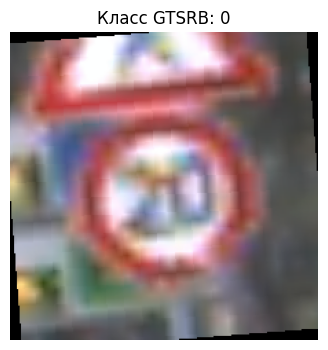

In [18]:
# Отображение одного дорожного знака после нормализации (денормализация для просмотра)
sign_x, sign_y = gtsrb_train[0]
sign_show = sign_x.permute(1,2,0).numpy()*np.array([0.229,0.224,0.225])+np.array([0.485,0.456,0.406])
plt.figure(figsize=(4,4)); plt.imshow(np.clip(sign_show,0,1)); plt.title(f"Класс GTSRB: {sign_y}"); plt.axis("off"); plt.show()

In [19]:
gtsrb_results = []
gtsrb_final_model = None
for n_epochs in [1,3,5]:
    print(f"\n===== Эксперимент: {n_epochs} эпох =====")
    # одинаковая начальная точка для честного сравнения
    model_g = make_resnet50(43, pretrained=True)
    criterion_g = nn.CrossEntropyLoss()
    optimizer_g = torch.optim.Adam(model_g.parameters(), lr=0.0001)
    last_train_acc = last_train_loss = 0.0
    for epoch in range(1, n_epochs+1):
        last_train_loss, last_train_acc = train_one_epoch(model_g, train_dl_gtsrb, criterion_g, optimizer_g, device)
        te_loss, te_acc, _, _ = evaluate_model(model_g, test_dl_gtsrb, criterion_g, device)
        print(f"Эпоха {epoch}/{n_epochs}: train acc={last_train_acc:.2%}, test acc={te_acc:.2%}, test loss={te_loss:.4f}")
    te_loss, te_acc, _, _ = evaluate_model(model_g, test_dl_gtsrb, criterion_g, device)
    gtsrb_results.append({"Эпохи":n_epochs, "Точность обучения, %":round(last_train_acc*100,2),
                          "Точность тестирования, %":round(te_acc*100,2), "Тестовая ошибка":round(te_loss,4)})
    gtsrb_final_model = model_g
    # Сохраняем лучшую по числу эпох (последний эксперимент — 5 эпох)
    if n_epochs == 5:
        torch.save({"state_dict": model_g.state_dict(), "num_classes":43, "class_names":gtsrb_classes}, OUT / "resnet50.pt")
gtsrb_table = pd.DataFrame(gtsrb_results)
display(gtsrb_table)
gtsrb_table.to_csv(OUT / "gtsrb_experiments.csv", index=False)


===== Эксперимент: 1 эпох =====
Эпоха 1/1: train acc=87.75%, test acc=98.14%, test loss=0.0693

===== Эксперимент: 3 эпох =====
Эпоха 1/3: train acc=88.23%, test acc=98.29%, test loss=0.0572
Эпоха 2/3: train acc=99.67%, test acc=98.88%, test loss=0.0401
Эпоха 3/3: train acc=99.86%, test acc=98.79%, test loss=0.0486

===== Эксперимент: 5 эпох =====
Эпоха 1/5: train acc=87.17%, test acc=97.44%, test loss=0.0937
Эпоха 2/5: train acc=99.63%, test acc=97.65%, test loss=0.0864
Эпоха 3/5: train acc=99.80%, test acc=98.08%, test loss=0.0673
Эпоха 4/5: train acc=99.87%, test acc=98.46%, test loss=0.0654
Эпоха 5/5: train acc=99.86%, test acc=98.67%, test loss=0.0485


,Эпохи,"Точность обучения, %","Точность тестирования, %",Тестовая ошибка
0,1,87.75,98.14,0.0693
1,3,99.86,98.79,0.0486
2,5,99.86,98.67,0.0485


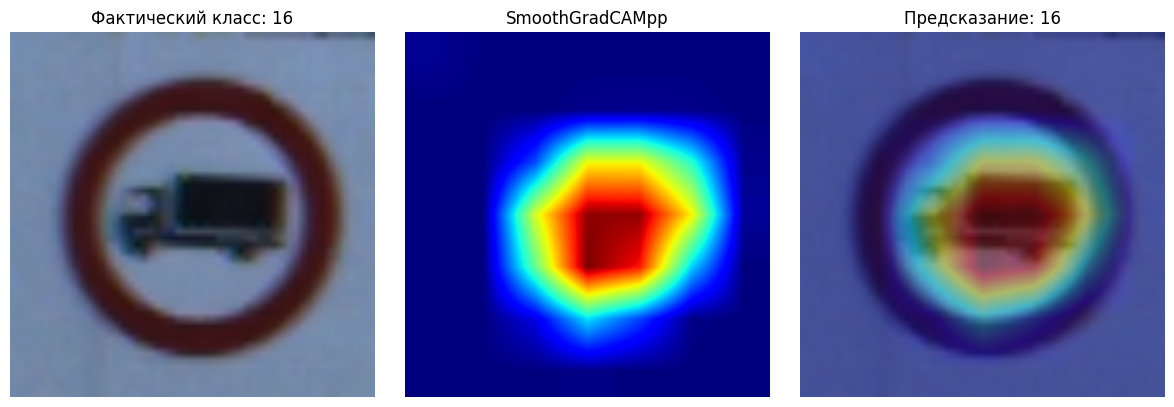

Сохранено: /content/results/sign.png /content/results/gtsrb_gradcam.png /content/results/resnet50.pt


In [20]:
# Выбираем тестовый знак, сохраняем исходное изображение sign.png и тепловую карту
# Датасет GTSRB хранит исходные изображения в ._samples; безопасно используем PIL-версию,
# если доступна, иначе восстанавливаем вид из тензора.
sign_img_tensor, sign_label = gtsrb_test_full[0]
sign_vis = sign_img_tensor.permute(1,2,0).numpy()*np.array([0.229,0.224,0.225])+np.array([0.485,0.456,0.406])
sign_vis = np.clip(sign_vis,0,1)
sign_pil = Image.fromarray((sign_vis*255).astype(np.uint8))
sign_pil.save(OUT / "sign.png")

gtsrb_final_model.eval()
sign_batch = sign_img_tensor.unsqueeze(0).to(device)
cam_sign = SmoothGradCAMpp(gtsrb_final_model, target_layer="layer4")
sign_logits = gtsrb_final_model(sign_batch)
sign_pred = int(sign_logits.argmax(1).item())
sign_map = cam_sign(sign_pred, sign_logits)[0].detach().cpu().squeeze().numpy()
sign_map = np.maximum(sign_map,0)
sign_map = (sign_map-sign_map.min())/(sign_map.max()-sign_map.min()+1e-8)
sign_heat = cv2.resize(sign_map,(sign_vis.shape[1],sign_vis.shape[0]))
sign_color = cv2.cvtColor(cv2.applyColorMap(np.uint8(255*sign_heat),cv2.COLORMAP_JET),cv2.COLOR_BGR2RGB)/255.0
sign_overlay = np.clip(0.6*sign_vis+0.4*sign_color,0,1)
plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(sign_vis); plt.title(f"Фактический класс: {sign_label}"); plt.axis("off")
plt.subplot(1,3,2); plt.imshow(sign_heat,cmap="jet"); plt.title("SmoothGradCAMpp"); plt.axis("off")
plt.subplot(1,3,3); plt.imshow(sign_overlay); plt.title(f"Предсказание: {sign_pred}"); plt.axis("off")
plt.tight_layout(); plt.savefig(OUT / "gtsrb_gradcam.png",dpi=170); plt.show()
print("Сохранено:", OUT/"sign.png", OUT/"gtsrb_gradcam.png", OUT/"resnet50.pt")

## Сохранение результатов и скачивание

Все результаты сохраняются в `/content/results`. Следующая ячейка создаёт ZIP-архив с отчётами, графиками, весами и таблицами. Сам `cat.jpg` также включается, если он найден в рабочей директории.

In [21]:
import zipfile
archive_path = Path("/content/результаты_практической_работы.zip") if Path("/content").exists() else Path("результаты_практической_работы.zip")
with zipfile.ZipFile(archive_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in OUT.rglob("*"):
        if p.is_file():
            zf.write(p, arcname=f"results/{p.name}")
    if Path("cat.jpg").exists():
        zf.write("cat.jpg", arcname="cat.jpg")
print("Архив создан:", archive_path)
try:
    from google.colab import files
    files.download(str(archive_path))
except Exception:
    print("В локальном Jupyter архив доступен по указанному пути.")

Архив создан: /content/результаты_практической_работы.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Итоговый вывод

После выполнения всех разделов заполните отчёт фактическими метриками и ответами по тепловым картам. Сравните результаты FashionMNIST, FGVCAircraft и GTSRB. Укажите, как число эпох повлияло на качество, и есть ли признаки переобучения: например, растущая точность обучения при ухудшении тестовой метрики или увеличении тестовой ошибки.

### Перечень файлов
- `fashionmnist_results.csv`, `fashionmnist_model.pt`, `fashionmnist_example.png`
- `output.jpg` — Grad-CAM для ResNet18
- `classification_report.txt`, `aircraft_confusion_matrix.png`, `aircraft_training_curves.png`, `aircraft_gradcam.png`, `aircraft_history.csv`
- `gtsrb_experiments.csv`, `sign.png`, `gtsrb_gradcam.png`, `resnet50.pt`